# FINAL OOS PERFORMANCE: BOMBA-GOAT @ Lynx

**Stockholm Lynx Hackathon 2026, team NewNordics.** Jaakko Pakarinen, Eemil Ylä-Nikkilä, Erik Joonas Salumäe, Kristofer Vaiksaar

We submitted one book: **50% BOMBASTRAT + 50% GOAT**. Lynx scored it on data we had never seen.
This report covers how that went, what made money, what lost money, and when.

**Data.** Lynx released two out-of-sample paths. Both are the same as our in-sample data up to 2016, and the same
as each other for 2017-2020. From **2021-01-04 they split** into two different futures that run to 2026-07-15.
So we look at three windows:

| window | dates | what it is |
|---|---|---|
| in-sample | 1995-01 to 2016-12 | data we built the model on |
| OOS shared | 2017-01 to 2020-12 | first out-of-sample stretch, the same in both paths |
| OOS path 1 / path 2 | 2021-01 to 2026-07 | two separate futures |

The **positions are the files we handed in** (`SUBMISSION/positions_outofsample{1,2}.csv`). The first check
below confirms that `SUBMISSION/model.py`, unchanged, regenerates them exactly. Every number uses the scoring
rules in Lynx's `evaluation.py`: a position dated t trades at the close of t+2, slippage is 0.02 daily std per
unit traded, and adjusted Sharpe = SR · (1 + SR/6 · skew − SR²/24 · excess kurtosis).

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import display, Markdown
import oos_lib as L

pd.set_option("display.precision", 2); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "legend.frameon": False})
COL = {"mix": "#1f3a5f", "BOMBA": "#d9822b", "GOAT": "#2a9d8f", "p1": "#1f3a5f", "p2": "#c0392b"}
PART_COL = {"BOMBA trend": "#d9822b", "BOMBA inflation": "#f2b134", "BOMBA twins": "#8c510a",
            "GOAT engine1_stop_trend": "#2a9d8f", "GOAT engine2_xs_momentum": "#76c7b7", "GOAT deadband": "#999999",
            "slippage": "#7f7f7f"}
NICE = {"BOMBA trend": "BOMBA: trend", "BOMBA inflation": "BOMBA: inflation", "BOMBA twins": "BOMBA: twins",
        "GOAT engine1_stop_trend": "GOAT: E1 stop-trend", "GOAT engine2_xs_momentum": "GOAT: E2 XS momentum",
        "GOAT deadband": "GOAT: deadband", "slippage": "slippage"}
OOS, SPLIT = L.OOS_START, L.SPLIT

def shade(ax, full=False):
    if full: ax.axvspan(pd.Timestamp("1995-01-01"), OOS, color="grey", alpha=.08, lw=0)
    ax.axvline(OOS, color="k", lw=.8, ls=":"); ax.axvline(SPLIT, color="k", lw=.8, ls="--")

S, P, R, RB, RG, G = {}, {}, {}, {}, {}, {}
for k in (1, 2):
    prices, macro, submitted = L.load_scenario(k)
    S[k] = dict(prices=prices, macro=macro, submitted=submitted)
    P[k] = L.all_parts(prices, macro)                                   # additive pieces of the book
    sub = L.to_pd(submitted)
    R[k] = L.daily(sub, prices)                                         # book daily P&L incl. slippage
    RB[k] = L.daily(2 * sum(v for n, v in P[k].items() if n.startswith("BOMBA")), prices)   # BOMBASTRAT alone
    RG[k] = L.daily(2 * sum(v for n, v in P[k].items() if n.startswith("GOAT")), prices)    # GOAT alone
    gross = {n: L.pnl_frames(p, prices)[0].sum(axis=1) for n, p in P[k].items()}
    gross["slippage"] = L.pnl_frames(sub, prices)[1].sum(axis=1)
    G[k] = pd.DataFrame(gross).fillna(0.0)                              # columns add up to R[k]
oos = lambda x: x[x.index >= OOS]

## 1. Integrity check: the scored positions come straight from the frozen model

We rerun `SUBMISSION/model.py` on each released path and compare with the submitted CSV. We also confirm that our
P&L engine gives the same daily returns as Lynx's `evaluation.py`, and that the pieces we split the book into
add back to it exactly.

In [2]:
import model as M
rows = []
for k in (1, 2):
    s = S[k]
    regen = M.final_positions(s["prices"], s["macro"]).drop("AsOfDate").to_numpy()
    subm = s["submitted"].drop("AsOfDate").to_numpy()
    ev_ret = L.to_pd(L.ev.calc_key_figures(s["submitted"], s["prices"], key_figures=["returns"])["returns"])["returns"]
    parts_sum = sum(P[k].values())
    rows.append({"path": k, "rows": len(subm), "max |model.py - submitted|": np.abs(regen - subm).max(),
                 "max |our P&L - evaluation.py|": (R[k].reindex(ev_ret.index) - ev_ret.fillna(0)).abs().max(),
                 "max |sum of pieces - book|": (parts_sum - L.to_pd(s["submitted"])).abs().max().max()})
display(pd.DataFrame(rows).set_index("path").style.format("{:.1e}", subset=[c for c in rows[0] if c.startswith("max")]))

,rows,max |model.py - submitted|,max |our P&L - evaluation.py|,max |sum of pieces - book|
path,,,,
1,8175,0.0e+00,1.4e-13,2.3e-13
2,8175,0.0e+00,1.8e-13,1.7e-13


All three differences are zero, up to floating-point error. The model was frozen, the scored positions are exactly what it
produces, and the breakdowns below add up exactly to the book.

## 2. Headline: Lynx key figures

In [3]:
def kf(sub, prices, a, b):
    s = sub.filter(pl.col("AsOfDate").is_between(pd.Timestamp(a).date(), pd.Timestamp(b).date()))
    return L.ev.calc_key_figures(s, prices)

wins = [("in-sample 1995-2016", "1995-01-01", "2016-12-31"), ("OOS shared 2017-2020", "2017-01-01", "2020-12-31"),
        ("OOS diverged 2021-2026", "2021-01-01", "2026-12-31"), ("OOS total 2017-2026", "2017-01-01", "2026-12-31")]
rows = []
for k in (1, 2):
    for name, a, b in wins:
        if k == 2 and name.startswith(("in-sample", "OOS shared")):
            continue
        r = kf(S[k]["submitted"], S[k]["prices"], a, b)
        rows.append({"path": "both" if name.startswith(("in-sample", "OOS shared")) else f"path {k}", "window": name,
                     **{c: r[c] for c in ["adjusted_sharpe", "sharpe", "sharpe_1d_lag", "skewness", "kurtosis", "av_holding", "position_bias"]}})
head = pd.DataFrame(rows).set_index(["path", "window"])
display(head)

adjusted_sharpe  sharpe  sharpe_1d_lag  skewness  kurtosis  av_holding  position_bias
path   window                                                                                                       
both   in-sample 1995-2016                1.15    1.40           1.39     -0.18      4.62       38.41           0.29
       OOS shared 2017-2020               0.52    0.58           0.56     -0.68      6.00       36.96           0.28
path 1 OOS diverged 2021-2026             0.84    1.28           1.24     -0.70      5.85       40.88           0.24
       OOS total 2017-2026                0.76    0.98           0.96     -0.69      5.92       39.10           0.26
path 2 OOS diverged 2021-2026             0.83    0.91           0.90     -0.27      4.39       43.19           0.29
       OOS total 2017-2026                0.69    0.77           0.77     -0.44      5.06       40.23           0.29

**Reading the table**

* Out of sample the book kept a **positive adjusted Sharpe in both paths: 0.76 (path 1) and 0.69 (path 2)** over
  2017-2026, against 1.15 in-sample. Keeping about 60-65% of the in-sample number is normal for a model tested on unseen data.
* The weak stretch was the **shared 2017-2020 window (0.52)**. It holds the two worst drawdowns: the 2018 trend reversal
  and the COVID crash. Both futures did better after the split, at about **0.83-0.84**.
* `sharpe_1d_lag` is about equal to `sharpe` everywhere. Delaying execution by one more day costs nothing, so no
  short-term or look-ahead edge is hiding in the score.
* The gap between Sharpe and *adjusted* Sharpe grew out of sample: skew went from −0.18 to about −0.5/−0.7 and kurtosis from
  4.6 to 5-6. Section 8 shows where this comes from. Holding period (about 39 days) and long bias (about 0.27) stayed where we built them.

## 3. P&L over the whole history

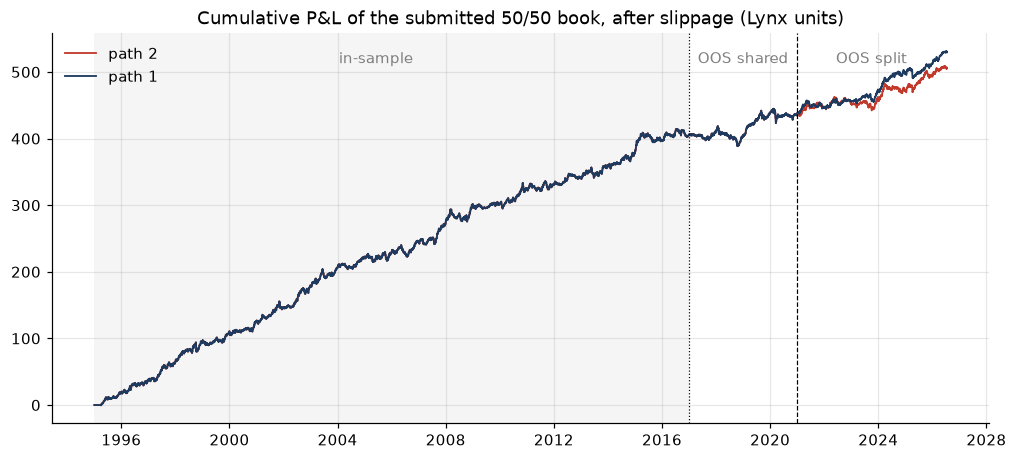

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for k in (2, 1):
    ax.plot(R[k].cumsum(), color=COL[f"p{k}"], lw=1.2, label=f"path {k}")
shade(ax, full=True)
ax.text(pd.Timestamp("2005-06-01"), ax.get_ylim()[1] * .92, "in-sample", ha="center", color="grey")
ax.text(pd.Timestamp("2019-01-01"), ax.get_ylim()[1] * .92, "OOS shared", ha="center", color="grey")
ax.text(pd.Timestamp("2023-10-01"), ax.get_ylim()[1] * .92, "OOS split", ha="center", color="grey")
ax.set_title("Cumulative P&L of the submitted 50/50 book, after slippage (Lynx units)"); ax.legend(loc="upper left")
plt.show()

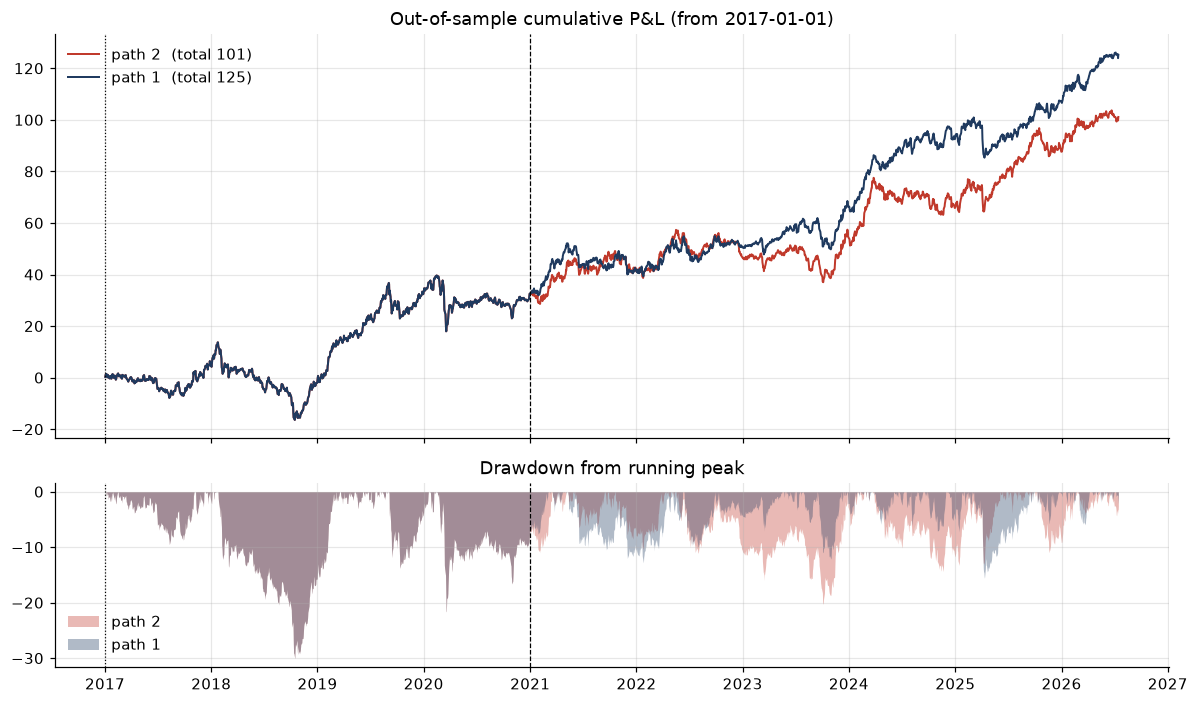

,adj. Sharpe,Sharpe,ann. P&L,ann. vol,skew,kurtosis,max DD,hit rate
path 1,0.76,0.99,13.16,13.27,-0.69,5.93,-30.09,0.55
path 2,0.69,0.78,10.63,13.63,-0.44,5.06,-30.09,0.53


In [5]:
fig, axs = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for k in (2, 1):
    eq = oos(R[k]).cumsum()
    axs[0].plot(eq, color=COL[f"p{k}"], lw=1.3, label=f"path {k}  (total {eq.iloc[-1]:.0f})")
    axs[1].fill_between(eq.index, eq - eq.cummax(), 0, color=COL[f"p{k}"], alpha=.35, lw=0, label=f"path {k}")
for a in axs: shade(a)
axs[0].set_title("Out-of-sample cumulative P&L (from 2017-01-01)"); axs[0].legend(loc="upper left")
axs[1].set_title("Drawdown from running peak"); axs[1].legend(loc="lower left")
axs[1].xaxis.set_major_locator(mdates.YearLocator()); axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"path {k}": L.stats(oos(R[k])) for k in (1, 2)}).T)

The book made about **13 units a year at about 13 units of volatility** in path 1, and about 10.6 units a year in path 2.
Most of the shortfall versus in-sample sits in the first two years. 2017 was flat to slightly up. In **2018 the book lost
30 units peak to trough (Jan to Oct)**, its deepest drawdown out of sample. After that it climbed steadily. Path 1 made
new highs almost every year from 2023. Path 2 went sideways from mid-2022 to late 2023, then picked up again in 2025-2026.

## 4. Adjusted Sharpe over time

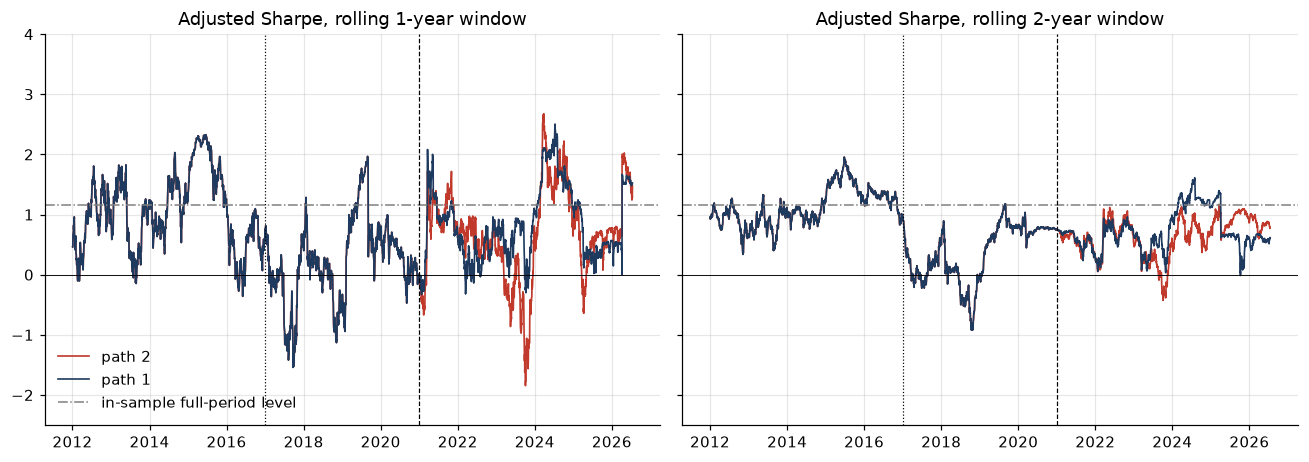

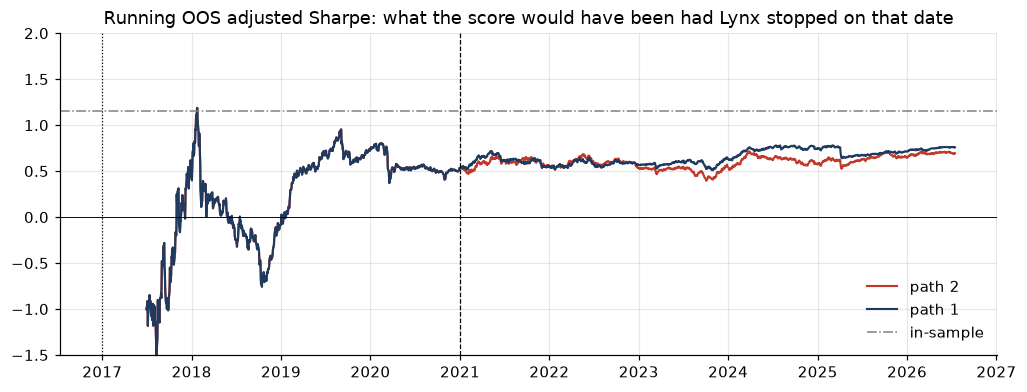

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, w, nm in [(axs[0], 260, "rolling 1-year"), (axs[1], 520, "rolling 2-year")]:
    for k in (2, 1):
        ax.plot(L.rolling_adj_sharpe(R[k], w)["2012":], color=COL[f"p{k}"], lw=1.1, label=f"path {k}")
    ax.axhline(head.loc[("both", "in-sample 1995-2016"), "adjusted_sharpe"], color="grey", lw=1, ls="-.", label="in-sample full-period level")
    ax.axhline(0, color="k", lw=.6); shade(ax); ax.set_title(f"Adjusted Sharpe, {nm} window"); ax.set_ylim(-2.5, 4)
axs[0].legend(loc="lower left"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
for k in (2, 1):
    ax.plot(L.expanding_adj_sharpe(oos(R[k])), color=COL[f"p{k}"], lw=1.4, label=f"path {k}")
ax.axhline(head.loc[("both", "in-sample 1995-2016"), "adjusted_sharpe"], color="grey", ls="-.", lw=1, label="in-sample")
ax.axhline(0, color="k", lw=.6); shade(ax); ax.set_ylim(-1.5, 2)
ax.set_title("Running OOS adjusted Sharpe: what the score would have been had Lynx stopped on that date"); ax.legend()
plt.show()

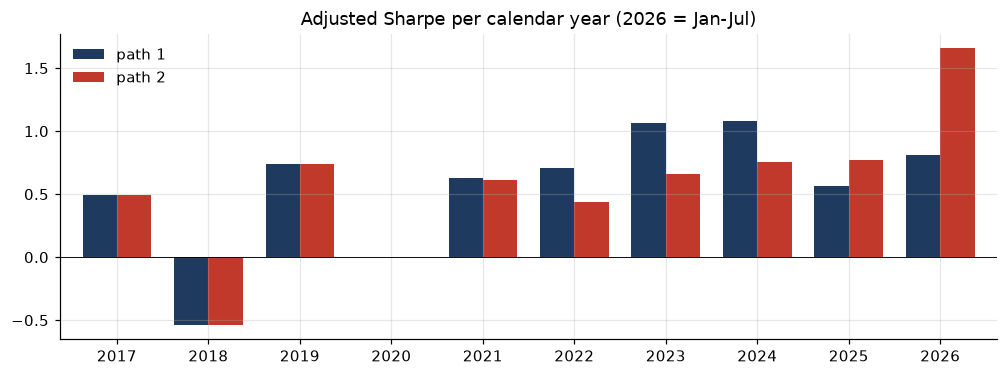

AsOfDate,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
path 1,0.49,-0.54,0.74,-9.08e-04,0.63,0.70,1.07,1.08,0.56,0.81
path 2,0.49,-0.54,0.74,-9.08e-04,0.61,0.44,0.66,0.76,0.77,1.66


In [7]:
yr = pd.DataFrame({f"path {k}": oos(R[k]).groupby(oos(R[k]).index.year).apply(L.adj_sharpe) for k in (1, 2)})
ax = yr.plot.bar(color=[COL["p1"], COL["p2"]], figsize=(11, 3.6), width=.75)
ax.axhline(0, color="k", lw=.6); ax.set_title("Adjusted Sharpe per calendar year (2026 = Jan-Jul)"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.show()
display(yr.T)

* The **running score** swings a lot in 2017 because the sample is still short. It sank again through the 2018 drawdown and
  has risen steadily since. It ends at 0.76 (path 1) and 0.69 (path 2).
* **2018 is the only clearly losing year.** 2020 ended flat (−0.1): COVID cost about 22 units, and the book won it
  back by year end.
* After the split, the **rolling 1-year adjusted Sharpe was above zero 94% of the time in path 1 and 83% in path 2**. Path 1's good run
  came in 2023-2024 (above 1). Path 2's came in 2025-2026 (1.66 in the first half of 2026).

## 5. Where the money came from: the components of the 50/50

The book is the exact sum of six pieces (each already at its 50% weight) plus slippage:

* **BOMBASTRAT**: *trend* (EWMAC + 12-month momentum, all assets), *inflation* (short bonds/stocks when CPI runs hot),
  *twins* (mean-reversion of the gap between commodity pairs that move together)
* **GOAT**: *engine 1* (EMA 10/100 long-only with a stretch-activated trailing stop, stocks and bonds), *engine 2*
  (12-month momentum ranked inside each asset class), *deadband* (the small effect of the 10% no-trade band)

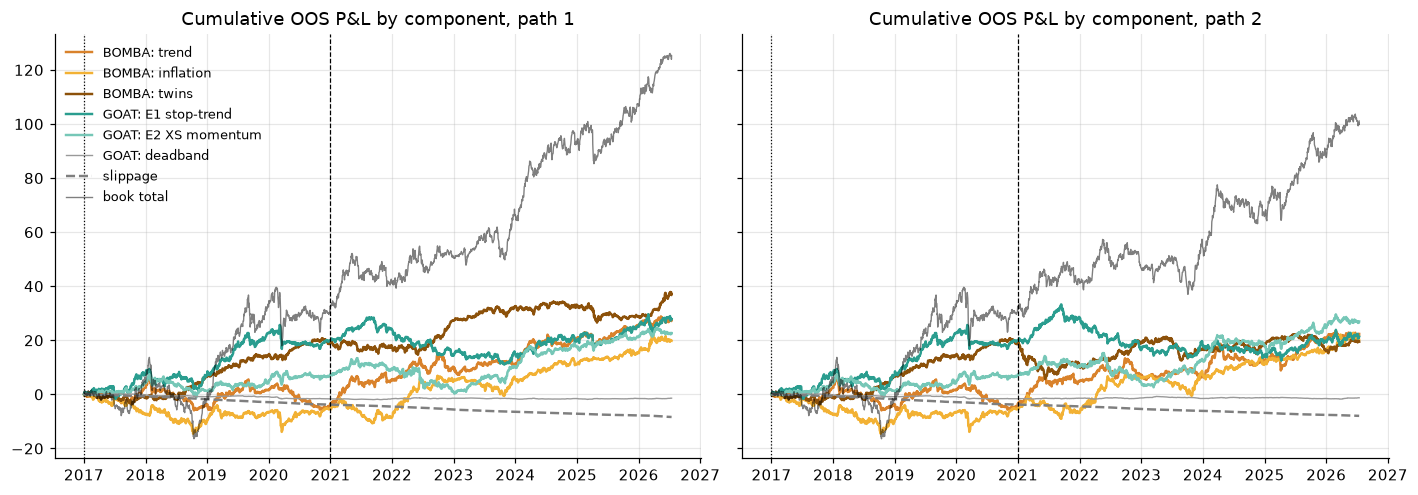

,path 1,path 1 share,path 2,path 2 share
BOMBA: trend,27.5,22%,22.4,22%
BOMBA: inflation,19.8,16%,20.2,20%
BOMBA: twins,37.1,30%,19.5,19%
GOAT: E1 stop-trend,27.9,22%,21.3,21%
GOAT: E2 XS momentum,22.7,18%,27.0,27%
GOAT: deadband,-1.4,-1%,-1.3,-1%
slippage,-8.4,-7%,-7.9,-8%
TOTAL,125.2,100%,101.1,100%


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, k in zip(axs, (1, 2)):
    cum = oos(G[k]).cumsum()
    for c in cum:
        ax.plot(cum[c], color=PART_COL[c], lw=1.6 if "deadband" not in c else .9,
                ls="--" if c == "slippage" else "-", label=NICE[c])
    ax.plot(oos(R[k]).cumsum(), color="k", lw=.9, alpha=.5, label="book total")
    shade(ax); ax.set_title(f"Cumulative OOS P&L by component, path {k}")
axs[0].legend(loc="upper left", fontsize=8.5); plt.tight_layout(); plt.show()

tab = pd.concat({f"path {k}": oos(G[k]).sum() for k in (1, 2)}, axis=1)
tab.index = [NICE[i] for i in tab.index]
tab.loc["TOTAL"] = tab.sum()
share = tab.div(tab.loc["TOTAL"]).add_suffix(" share")
display(pd.concat([tab, share], axis=1)[["path 1", "path 1 share", "path 2", "path 2 share"]]
        .style.format({"path 1": "{:.1f}", "path 2": "{:.1f}", "path 1 share": "{:.0%}", "path 2 share": "{:.0%}"}))

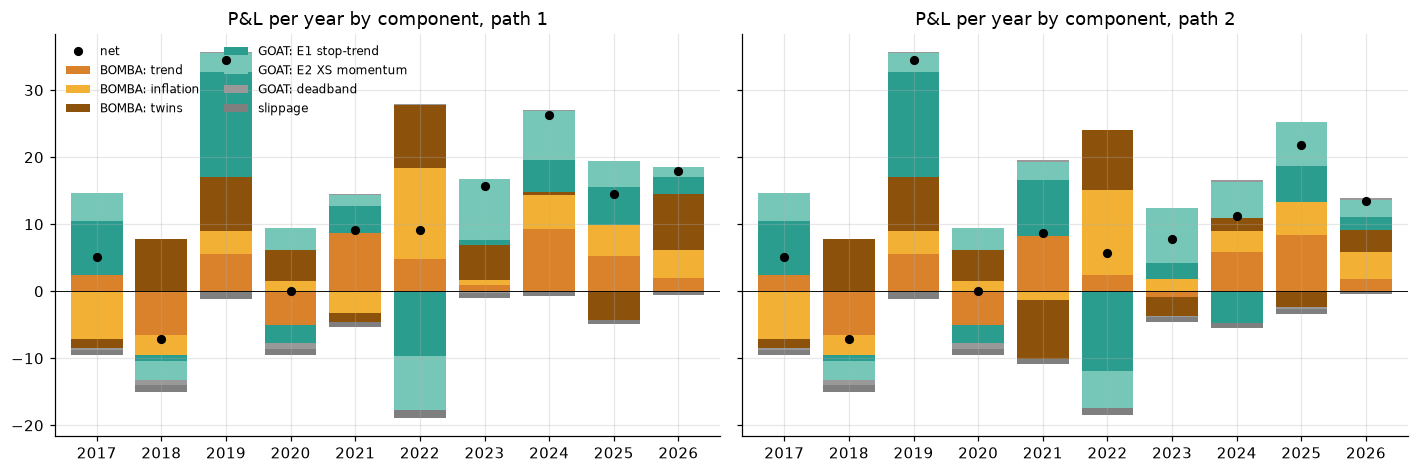

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, k in zip(axs, (1, 2)):
    y = oos(G[k]).groupby(oos(G[k]).index.year).sum()
    y.rename(columns=NICE).plot.bar(stacked=True, ax=ax, color=[PART_COL[c] for c in y.columns], width=.8, legend=False)
    ax.plot(range(len(y)), y.sum(axis=1).values, "ko", ms=5, label="net")
    ax.axhline(0, color="k", lw=.6); ax.set_title(f"P&L per year by component, path {k}"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axs[0].legend(*axs[0].get_legend_handles_labels(), fontsize=8, loc="upper left", ncol=2); plt.tight_layout(); plt.show()

**Everything that should earn did earn.** Every signal piece is positive over the full OOS period in both paths, and
no single piece carried the result:

* In **path 1** the profit splits roughly evenly between the two books. BOMBASTRAT's **twins** was the largest piece
  (about 37 units), followed by GOAT engine 1, BOMBA trend, engine 2 and inflation.
* In **path 2** the six pieces are even more alike (about 20-27 units each). GOAT engine 2 (momentum ranked within each class) led.
* **Inflation** paid off mainly in **2022** (+13 in both paths). This is the CPI-surprise regime it was built for. It lost in
  2017 (−7) while CPI noise was mostly mean-reverting.
* **Slippage cost about 8 units in total**, under 1 unit a year. The glide and deadband did their job. The deadband's own
  P&L is about −1.4: the small price paid for trading less.

### The two books on their own

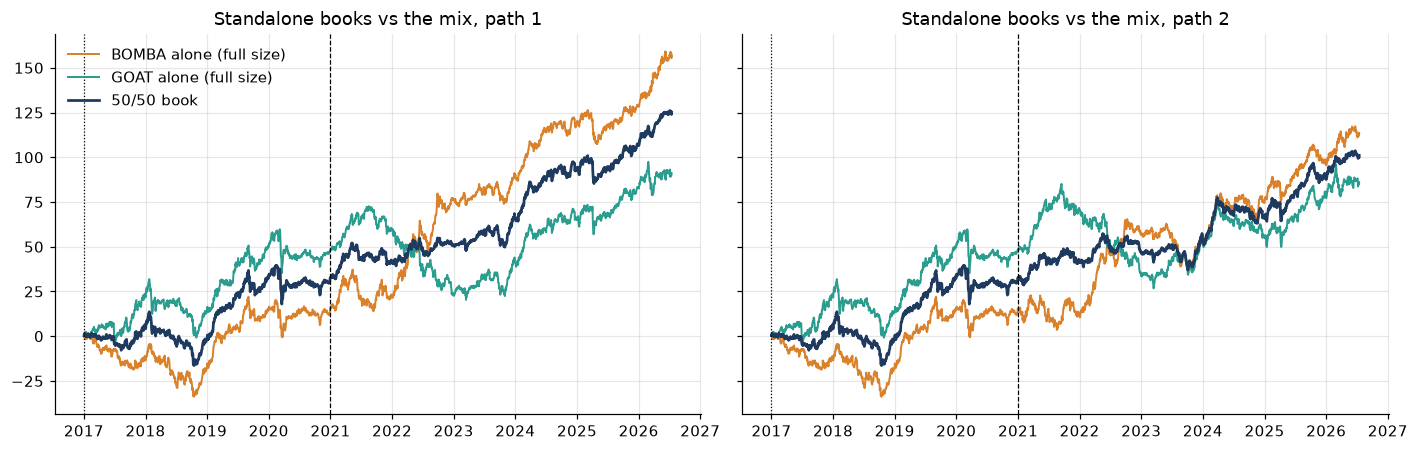

window     in-sample OOS shared OOS diverged        OOS total       
path            both       both       path 1 path 2    path 1 path 2
book                                                                
50/50 book      1.15       0.53         0.84   0.83      0.76   0.69
BOMBASTRAT      1.00       0.24         1.33   0.98      0.92   0.68
GOAT            1.05       0.62         0.42   0.37      0.51   0.49

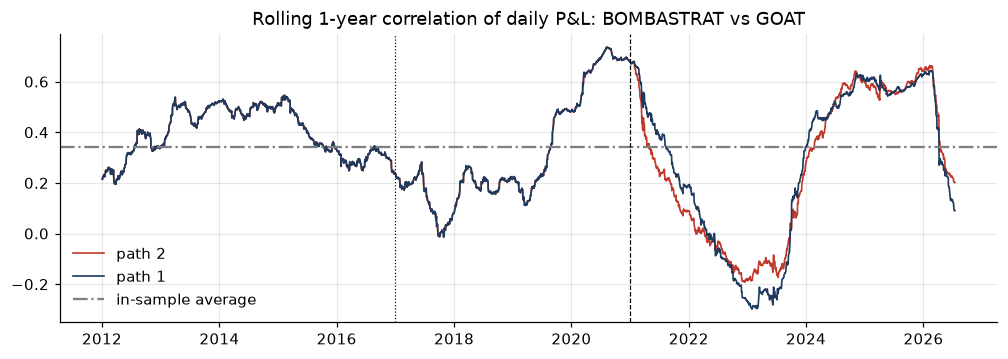

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, k in zip(axs, (1, 2)):
    for nm, r in [("BOMBA", RB[k]), ("GOAT", RG[k])]:
        ax.plot(oos(r).cumsum(), color=COL[nm], lw=1.3, label=f"{nm} alone (full size)")
    ax.plot(oos(R[k]).cumsum(), color=COL["mix"], lw=1.8, label="50/50 book")
    shade(ax); ax.set_title(f"Standalone books vs the mix, path {k}")
axs[0].legend(loc="upper left"); plt.tight_layout(); plt.show()

rows = []
for k in (1, 2):
    for nm, r in [("BOMBASTRAT", RB[k]), ("GOAT", RG[k]), ("50/50 book", R[k])]:
        for wn, m in [("in-sample", r.index < OOS), ("OOS shared", (r.index >= OOS) & (r.index < SPLIT)),
                      ("OOS diverged", r.index >= SPLIT), ("OOS total", r.index >= OOS)]:
            if k == 2 and wn in ("in-sample", "OOS shared"): continue
            rows.append({"book": nm, "path": "both" if wn in ("in-sample", "OOS shared") else f"path {k}",
                         "window": wn, "adj. Sharpe": L.adj_sharpe(r[m])})
books = pd.DataFrame(rows).pivot_table(index="book", columns=["window", "path"], values="adj. Sharpe")
books = books[[c for c in [("in-sample", "both"), ("OOS shared", "both"), ("OOS diverged", "path 1"), ("OOS diverged", "path 2"),
                           ("OOS total", "path 1"), ("OOS total", "path 2")]]]
display(books)

fig, ax = plt.subplots(figsize=(11, 3.4))
for k in (2, 1):
    ax.plot(RB[k].rolling(260).corr(RG[k])["2012":], color=COL[f"p{k}"], lw=1.1, label=f"path {k}")
ax.axhline(RB[1][RB[1].index < OOS].corr(RG[1][RG[1].index < OOS]), color="grey", ls="-.", label="in-sample average")
shade(ax); ax.set_title("Rolling 1-year correlation of daily P&L: BOMBASTRAT vs GOAT"); ax.legend(); plt.show()

**The 50/50 blend did what it was meant to do.** Which book was better flipped between windows:

* **2017-2020: GOAT carried the book** (0.62 vs 0.24). BOMBASTRAT's trend piece was hit by the 2018 reversal and the
  2020 crash, and inflation was hit in 2017.
* **2021-2026: BOMBASTRAT carried the book** (1.33 in path 1, 0.98 in path 2), while GOAT faded to about 0.4. Trend and inflation
  thrived in the 2021-2022 trends. GOAT, which leans long stocks and bonds, struggled in 2022-2023.

No single book was best in every window, and the P&L correlation stayed low (about 0.25 OOS, below the 0.34 in-sample).
That made the mix steadier than either book in most windows. In path 2 the blend's total OOS score (0.69) beat both
standalone books (BOMBA 0.68, GOAT 0.49). In path 1, BOMBASTRAT alone would have scored a bit higher (0.92 vs 0.76). We could
not have known that before the split, and in 2017-2020 the same choice would have hurt.

## 6. Where the money came from: asset classes and instruments

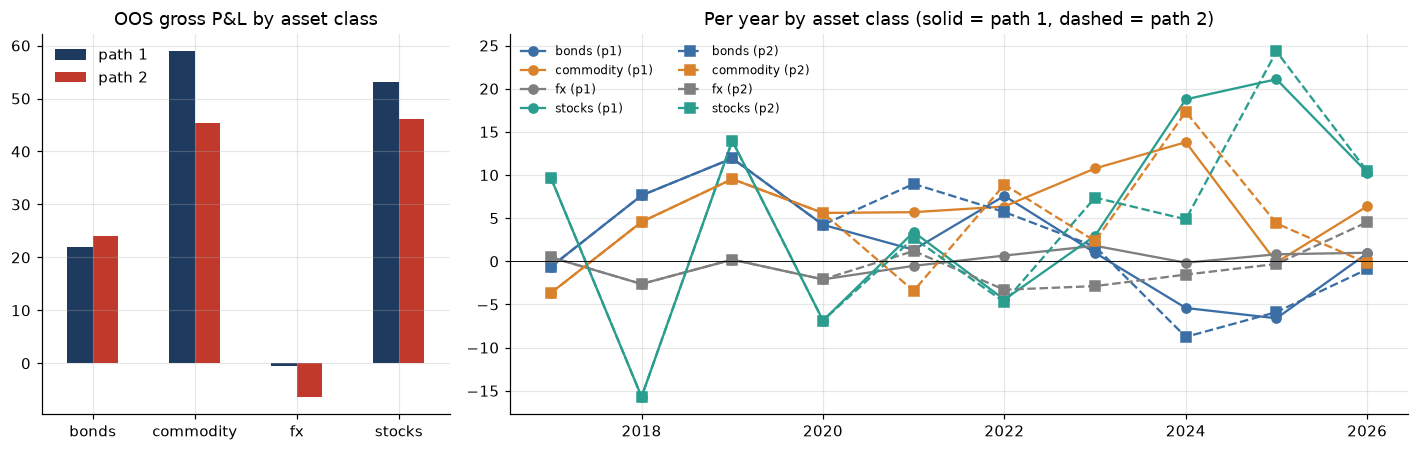

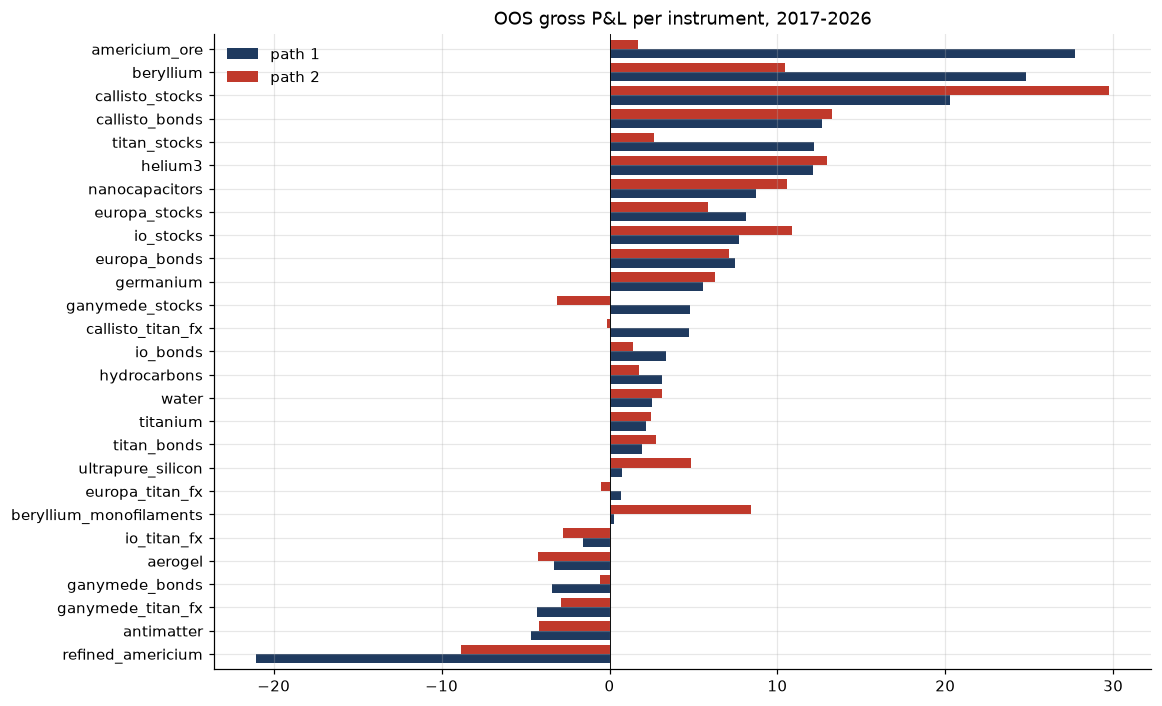

In [11]:
gi = {k: oos(L.pnl_frames(L.to_pd(S[k]["submitted"]), S[k]["prices"])[0]) for k in (1, 2)}
cls = pd.DataFrame({f"path {k}": gi[k].T.groupby(L.sector).sum().T.sum() for k in (1, 2)})
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
cls.plot.bar(ax=axs[0], color=[COL["p1"], COL["p2"]], rot=0); axs[0].set_title("OOS gross P&L by asset class")
for k, m in ((1, "o"), (2, "s")):
    y = gi[k].T.groupby(L.sector).sum().T
    y = y.groupby(y.index.year).sum()
    for c, col in zip(y.columns, ["#3b6ea5", "#d9822b", "#7f7f7f", "#2a9d8f"]):
        axs[1].plot(y.index, y[c], marker=m, color=col, ls="-" if k == 1 else "--", label=f"{c} (p{k})")
axs[1].axhline(0, color="k", lw=.6); axs[1].set_title("Per year by asset class (solid = path 1, dashed = path 2)")
axs[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

inst = pd.DataFrame({f"path {k}": gi[k].sum() for k in (1, 2)}).sort_values("path 1")
ax = inst.plot.barh(figsize=(11, 7.5), color=[COL["p1"], COL["p2"]], width=.8)
ax.axvline(0, color="k", lw=.6); ax.set_title("OOS gross P&L per instrument, 2017-2026"); plt.show()

In [12]:
rows = []
for k in (1, 2):
    held = L.to_pd(S[k]["submitted"]).shift(2).reindex(gi[k].index)
    rows.append({"path": f"path {k}", "from long positions": gi[k].where(held > 0).sum().sum(),
                 "from short positions": gi[k].where(held < 0).sum().sum()})
ls_ = pd.DataFrame(rows).set_index("path"); display(ls_)

,from long positions,from short positions
path,,
path 1,127.38,6.18
path 2,106.88,2.17


* **Stocks and commodities made most of the money** (about 45-59 units each). Bonds added about 22-24. FX was flat to slightly
  negative: about −0.5 in path 1 and −6 in path 2. FX is traded only by BOMBASTRAT's trend piece and GOAT's ranked momentum,
  and neither found much in it.
* **The best instruments**: callisto_stocks (largest in path 2, about +30), americium_ore and beryllium (path 1), callisto_bonds,
  helium3, titan_stocks, nanocapacitors.
* **The one real problem**: refined_americium (−21 in path 1, −9 in path 2). It is the main loser in both paths, and almost
  all of that loss comes from the **twins** piece, which trades it against americium_ore. In path 1, twins lost 22 on the
  refined leg and made 31 on the ore leg, so the pair still netted +9. In path 2 the pair lost about 3 (−6 refined, +4 ore).
* **Almost all profit came from the long side** (about 107-127 units long vs about 2-6 units short). The short side mostly
  hedged and diversified the longs rather than earning on its own. That fits the built-in long tilt of about 0.27-0.29 and the
  upward drift of the stocks and bonds in this data.

## 7. Good and bad periods

In [13]:
for k in (1, 2):
    r = oos(R[k]); dd = L.drawdowns(r, 5)
    drv = []
    for _, d in dd.iterrows():
        w = G[k].loc[str(d.peak):str(d.trough)].sum()
        a = gi[k].loc[str(d.peak):str(d.trough)].sum().sort_values()
        drv.append({"worst piece": f"{NICE[w.idxmin()]} ({w.min():.1f})",
                    "worst assets": ", ".join(f"{i} ({v:.1f})" for i, v in a.head(3).items())})
    display(Markdown(f"**Five deepest OOS drawdowns, path {k}**"))
    display(pd.concat([dd, pd.DataFrame(drv)], axis=1).style.format({"depth": "{:.1f}"}).hide(axis="index"))

**Five deepest OOS drawdowns, path 1**

peak,trough,recovered,depth,days to trough,worst piece,worst assets
2018-01-23,2018-10-15,2019-03-07,-30.1,188,BOMBA: trend (-11.8),"titan_stocks (-5.8), ganymede_bonds (-4.1), europa_stocks (-3.8)"
2020-02-14,2020-03-18,2021-03-03,-21.7,23,BOMBA: inflation (-7.7),"titan_stocks (-6.6), callisto_stocks (-5.7), ganymede_stocks (-5.4)"
2025-03-05,2025-04-11,2025-09-15,-15.6,27,GOAT: E1 stop-trend (-4.8),"io_stocks (-2.6), europa_stocks (-2.2), americium_ore (-2.0)"
2019-09-03,2019-10-11,2020-01-17,-13.8,28,GOAT: E1 stop-trend (-5.0),"europa_bonds (-3.4), io_bonds (-2.9), ganymede_bonds (-2.4)"
2021-05-10,2022-01-25,2022-05-04,-12.8,186,GOAT: E1 stop-trend (-4.7),"refined_americium (-12.4), beryllium_monofilaments (-4.1), callisto_stocks (-3.1)"


**Five deepest OOS drawdowns, path 2**

peak,trough,recovered,depth,days to trough,worst piece,worst assets
2018-01-23,2018-10-15,2019-03-07,-30.1,188,BOMBA: trend (-11.8),"titan_stocks (-5.8), ganymede_bonds (-4.1), europa_stocks (-3.8)"
2020-02-14,2020-03-18,2021-03-17,-21.7,23,BOMBA: inflation (-7.7),"titan_stocks (-6.6), callisto_stocks (-5.7), ganymede_stocks (-5.4)"
2022-05-17,2023-10-05,2023-12-27,-20.3,362,GOAT: E1 stop-trend (-8.1),"beryllium (-8.3), aerogel (-3.4), io_stocks (-3.1)"
2024-03-26,2024-11-20,2025-06-04,-14.4,171,BOMBA: trend (-5.6),"americium_ore (-7.2), europa_stocks (-3.6), beryllium (-1.7)"
2019-09-03,2019-10-11,2020-01-17,-13.8,28,GOAT: E1 stop-trend (-5.0),"europa_bonds (-3.4), io_bonds (-2.9), ganymede_bonds (-2.4)"


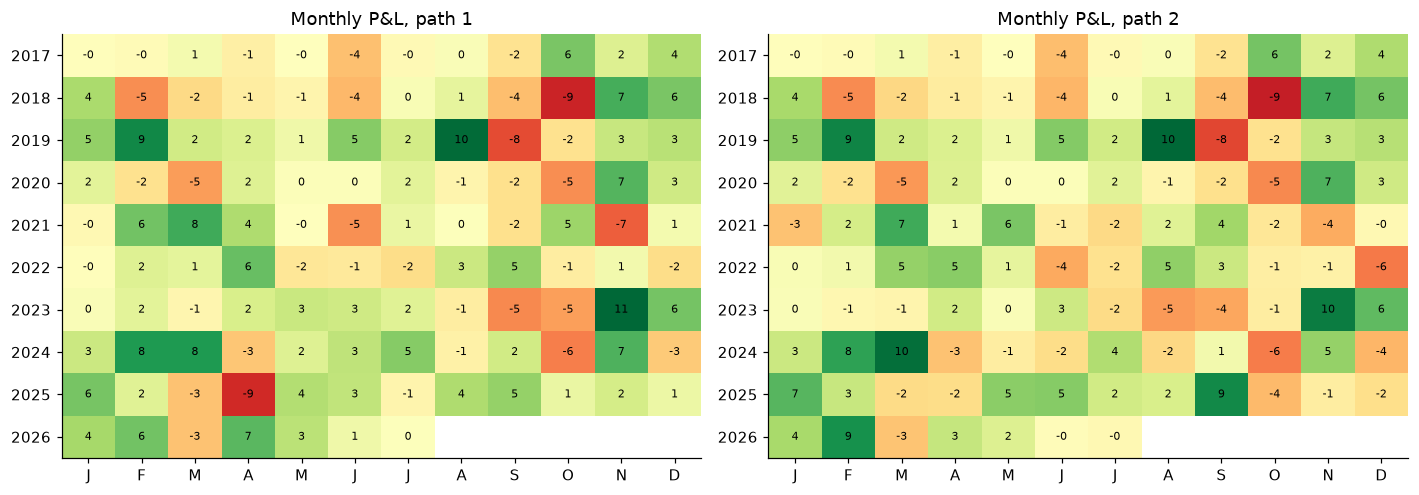

path 1: positive months **62%**, best month 10.7 (2023-11), worst month -9.1 (2018-10), average up month 3.5, average down month -2.8

path 2: positive months **55%**, best month 10.5 (2019-08), worst month -9.1 (2018-10), average up month 3.7, average down month -2.6

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, k in zip(axs, (1, 2)):
    m = oos(R[k]).resample("ME").sum()
    tbl = pd.DataFrame({"y": m.index.year, "m": m.index.month, "v": m.values}).pivot(index="y", columns="m", values="v")
    lim = np.nanmax(np.abs(tbl.values))
    im = ax.imshow(tbl.values, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(12)); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_yticks(range(len(tbl))); ax.set_yticklabels(tbl.index)
    for (i, j), v in np.ndenumerate(tbl.values):
        if not np.isnan(v): ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5)
    ax.grid(False); ax.set_title(f"Monthly P&L, path {k}")
plt.tight_layout(); plt.show()

for k in (1, 2):
    m = oos(R[k]).resample("ME").sum()
    display(Markdown(f"path {k}: positive months **{(m > 0).mean():.0%}**, best month {m.max():.1f} ({m.idxmax():%Y-%m}), "
                     f"worst month {m.min():.1f} ({m.idxmin():%Y-%m}), average up month {m[m > 0].mean():.1f}, average down month {m[m < 0].mean():.1f}"))

**The bad periods had one shape: a sharp break in a trend that had been running.**

* **2018 (−30, Jan-Oct, both paths).** Stocks reversed after a strong 2017 trend (titan, europa and ganymede stocks), and bond
  trends flipped. BOMBA trend lost about 12 units, GOAT's two engines about 14 between them, and inflation 6. Only twins made
  money. This is the textbook bad year for trend following: a long trend followed by a choppy, sideways reversal.
* **COVID, Feb-Mar 2020 (−22 in 23 trading days).** The long stock exposure in GOAT and the inflation piece's bond and stock
  positions all hit at once, and diversification across pieces did not help in the crash. The trend pieces then turned
  around and won it all back by early 2021.
* **Path 2, May 2022 to Oct 2023 (−20, slow).** GOAT's engines bled for 16 months (beryllium −8, aerogel, io_stocks) while
  markets chopped without trend. BOMBA lost only about 3 units over the window. The book's drawdown (−20) was far shallower than GOAT's own at full size (−31).
* **Path 1, Mar-Apr 2025 (−16 in 27 days)** and **path 2, Mar-Nov 2024 (−14)**: a stock sell-off and a reversal in americium_ore.

The **good periods** were long, steady trends: 2019 (+34 in both paths, the best year), and 2023-2024 in path 1 and
2025-2026 in path 2, when all six pieces made money together.

## 8. Return distribution: why adjusted Sharpe sits below Sharpe

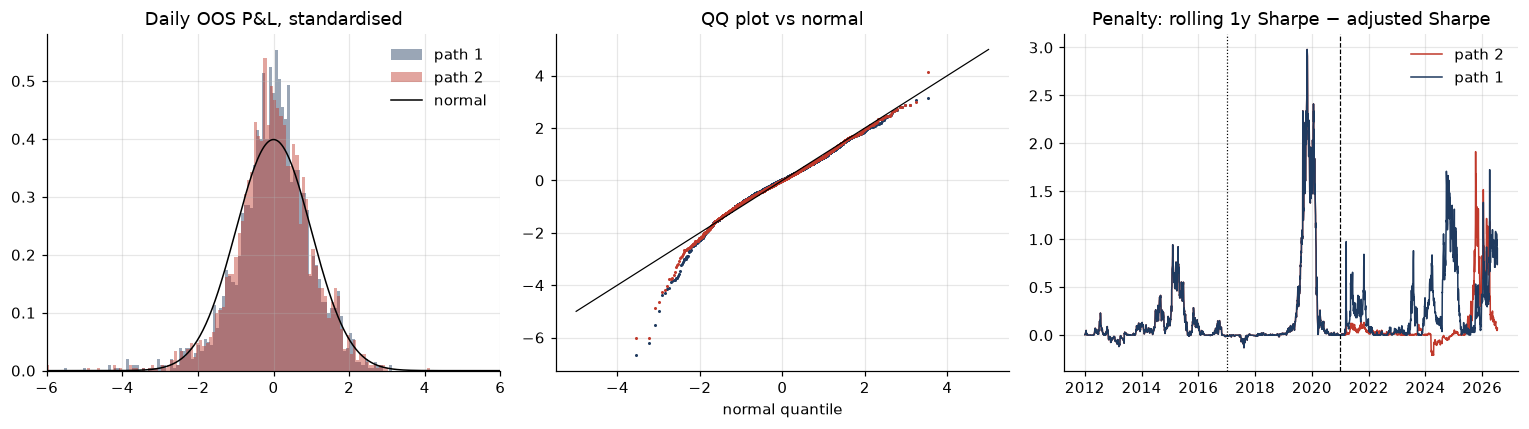

**Worst five OOS days per path**

path,date,P&L
path 1,2025-04-07,-5.45
path 1,2020-03-12,-5.06
path 1,2025-04-04,-4.50
path 1,2019-09-05,-4.06
path 1,2018-03-01,-3.55
path 2,2020-03-12,-5.06
path 2,2025-04-07,-5.04
path 2,2019-09-05,-4.06
path 2,2025-04-04,-3.90
path 2,2018-03-01,-3.55


,adj. Sharpe,without the 10 worst days,skew without them,kurtosis without them
path,,,,
1,0.76,1.19,-0.28,3.91
2,0.69,1.07,-0.09,3.56


In [15]:
from scipy import stats as st
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for k in (1, 2):
    r = oos(R[k]); z = (r - r.mean()) / r.std()
    axs[0].hist(z, bins=120, density=True, alpha=.45, color=COL[f"p{k}"], label=f"path {k}")
    q = np.sort(z.values); t = st.norm.ppf((np.arange(len(q)) + .5) / len(q))
    axs[1].plot(t, q, ".", ms=2, color=COL[f"p{k}"], label=f"path {k}")
xs = np.linspace(-6, 6, 300); axs[0].plot(xs, st.norm.pdf(xs), "k", lw=1, label="normal")
axs[0].set_xlim(-6, 6); axs[0].set_title("Daily OOS P&L, standardised"); axs[0].legend()
axs[1].plot([-5, 5], [-5, 5], "k", lw=.8); axs[1].set_title("QQ plot vs normal"); axs[1].set_xlabel("normal quantile")
rs = {f"path {k}": L.rolling_adj_sharpe(R[k], 260) for k in (1, 2)}
for k in (2, 1):
    s = R[k].rolling(260).mean() / R[k].rolling(260).std() * np.sqrt(260)
    axs[2].plot((s - rs[f"path {k}"])["2012":], color=COL[f"p{k}"], lw=1, label=f"path {k}")
shade(axs[2]); axs[2].set_title("Penalty: rolling 1y Sharpe − adjusted Sharpe"); axs[2].legend()
plt.tight_layout(); plt.show()

r_all = pd.concat({f"path {k}": oos(R[k]) for k in (1, 2)}, axis=1)
worst = pd.concat({f"path {k}": oos(R[k]).nsmallest(5) for k in (1, 2)}).rename("P&L").reset_index()
worst.columns = ["path", "date", "P&L"]; display(Markdown("**Worst five OOS days per path**")); display(worst.style.hide(axis="index").format({"P&L": "{:.2f}", "date": "{:%Y-%m-%d}"}))

trim = []
for k in (1, 2):
    r = oos(R[k]); lo = r.nsmallest(10).index
    trim.append({"path": k, "adj. Sharpe": L.adj_sharpe(r), "without the 10 worst days": L.adj_sharpe(r.drop(lo)),
                 "skew without them": r.drop(lo).skew(), "kurtosis without them": r.drop(lo).kurt() + 3})
display(pd.DataFrame(trim).set_index("path"))

The OOS returns have **fatter left tails than in-sample**. The QQ plot bends down on the left, and most of the bend
comes from a handful of days. Of the ten worst, three or four fall in **March 2020**, two in **April 2025**, and the rest in early 2018 and September 2019. Under the adjusted-Sharpe
formula those days cost twice: they lower the mean and they raise the skew and kurtosis penalty. Drop the ten worst days
out of about 2,500 and the adjusted Sharpe rises sharply. The weakness is **a few crash days hitting the long stock tilt**,
not a broad loss of the signals. The penalty (right panel) has a median of about zero and jumps in 2018, 2020 and 2025.

## 9. Was the risk target held?

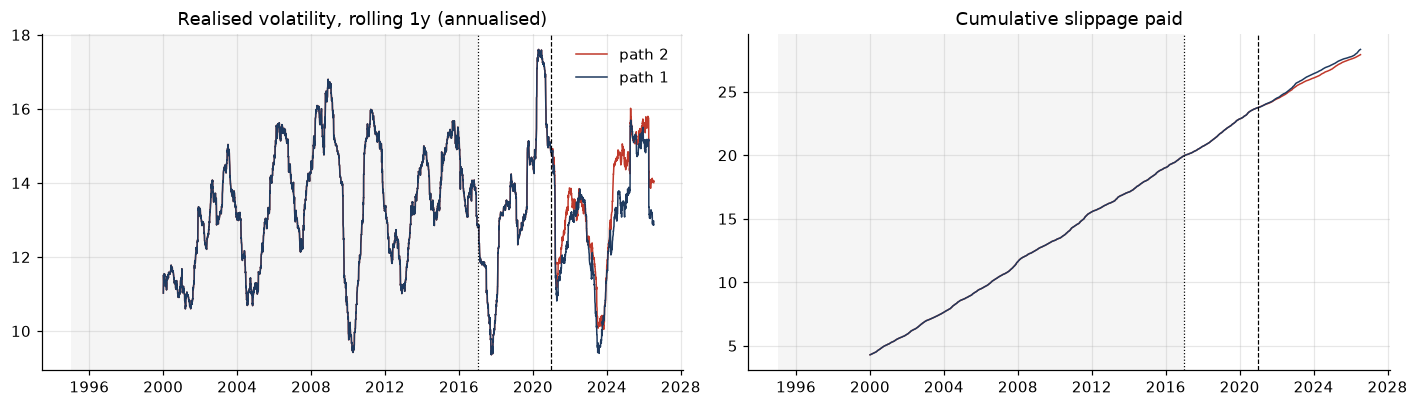

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for k in (2, 1):
    axs[0].plot((R[k].rolling(260).std() * np.sqrt(260))["2000":], color=COL[f"p{k}"], lw=1, label=f"path {k}")
    pos = L.to_pd(S[k]["submitted"])
    _, slip = L.pnl_frames(pos, S[k]["prices"])
    axs[1].plot(-slip.sum(axis=1).cumsum()["2000":], color=COL[f"p{k}"], lw=1, label=f"path {k}")
for a in axs: shade(a, full=True)
axs[0].set_title("Realised volatility, rolling 1y (annualised)"); axs[1].set_title("Cumulative slippage paid")
axs[0].legend(); plt.tight_layout(); plt.show()

Realised volatility averaged about 13.3 out of sample, against 13.4 in-sample, and moved between about 9 and 18. The ex-ante covariance scaling kept risk
roughly constant, with a short spike in 2020. Slippage built up at about the same rate as in-sample (about 0.85 vs 0.91 units a year), so trading
costs were no surprise out of sample.

## 10. Overall assessment

**Result.** The frozen 50/50 BOMBASTRAT + GOAT book scored an **adjusted Sharpe of 0.76 (path 1) and 0.69 (path 2)** on
2017-2026 data it had never seen, with a plain Sharpe of 0.98 / 0.77. It had eight profitable calendar years out of
ten (2018 the only real loss, 2020 flat), lost no edge from a one-day execution delay, and paid less than 1 unit a year in costs.

**What worked**
1. *Diversified sources of profit.* All six signal pieces made money out of sample in both paths, and none supplied more than
   about 30% of the profit. Nothing in the result rests on one lucky signal.
2. *The 50/50 blend.* GOAT carried 2017-2020 and BOMBASTRAT carried 2021-2026. The low correlation between them (about 0.25)
   kept the book positive in every multi-year window. Picking one book in 2016 would have been a coin flip that depended on the window.
3. *Inflation in 2022.* The inflation piece made its biggest gain exactly in the high-inflation regime it was built for.
4. *Costs.* Glide plus deadband kept slippage small and stable.

**What did not work**
1. *Sudden reversals.* 2018 and March 2020 caused most of the gap to in-sample. Both are sharp breaks in trends that had been running, the
   classic weak spot of trend-following books. Our long tilt in stocks and bonds made the crash days worse.
2. *Left tail.* Skew and kurtosis got worse out of sample, so the adjusted-Sharpe penalty is larger than in-sample. A few days
   explain most of it.
3. *refined_americium and FX.* One commodity pair and the FX class lost money in both paths.

**What we would try next** (not tested here, and the frozen model was not changed)
* A crash brake on the long tilt, such as cutting long exposure in stocks when volatility jumps. This targets exactly the days that cost the most.
* A cap or a break check on twins pairs whose gap keeps widening (the americium case).
* Dropping FX from engine 2's ranked momentum, or giving it lower weight.

*Reproduce:* `pip install polars pandas numpy pyarrow matplotlib scipy nbconvert`, then run this notebook from
`FINAL_OOS_PERFORMANCE/`. The data lives in `data/*_outofsample{1,2}.csv`, the submitted positions in `SUBMISSION/positions_outofsample{1,2}.csv`.